In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

DATASETS = {
    "bci2a": 9,
    "eegmmidb": 15,
    "weibo": 10,
    "zhou": 10,
}

SCENARIOS = [
    "Intra-subject",
    "Cross-session",
    "Cross-subject",
]

REPRESENTATIONS = [
    "Statistical",
    "Temporal",
    "Spectral",
    "Wavelet",
    "Covariance",
    "CSP-6",
    "Riemannian",
    "Fused",
]

MODELS = [
    "Logistic Regression",
    "SVM",
    "Random Forest",
    "MLP Small",
    "MLP Medium",
    "MLP Large",
]

BANDS = [
    "1–38 Hz",
    "Delta",
    "Theta",
    "Alpha",
    "Beta",
    "Gamma",
]

In [3]:
scenario_means = {
    "Intra-subject": 0.85,
    "Cross-session": 0.70,
    "Cross-subject": 0.42,
}

representation_effects = {
    rep: effect
    for rep, effect in zip(
        REPRESENTATIONS,
        [0.00, -0.03, 0.03, -0.02, 0.01, 0.05, 0.06, 0.07],
    )
}

model_effects = {
    model: effect
    for model, effect in zip(
        MODELS,
        [0.00, 0.03, -0.02, 0.01, 0.02, 0.025],
    )
}

band_effects = {
    band: effect
    for band, effect in zip(
        BANDS,
        [0.02, -0.08, -0.04, 0.02, 0.04, -0.03],
    )
}

rows = []

for dataset, n_subjects in DATASETS.items():
    for scenario in SCENARIOS:
        for subject in range(1, n_subjects + 1):

            subject_effect = rng.normal(0, 0.07)

            for representation in REPRESENTATIONS:
                for model in MODELS:
                    for band in BANDS:

                        ba = (
                            scenario_means[scenario]
                            + subject_effect
                            + representation_effects[representation]
                            + model_effects[model]
                            + band_effects[band]
                            + rng.normal(0, 0.035)
                        )

                        ba = np.clip(ba, 0.05, 0.99)

                        rows.append({
                            "Dataset": dataset,
                            "Scenario": scenario,
                            "Subject": subject,
                            "Representation": representation,
                            "Model": model,
                            "Band": band,
                            "Balanced Accuracy": ba,
                            "Macro-F1": np.clip(
                                ba + rng.normal(-0.02, 0.02), 0, 1
                            ),
                            "AUC": np.clip(
                                ba + rng.normal(0.08, 0.025), 0, 1
                            ),
                        })

synthetic_results = pd.DataFrame(rows)

print(f"Generated {len(synthetic_results):,} synthetic results")
synthetic_results.head()

Generated 38,016 synthetic results


,Dataset,Scenario,Subject,Representation,Model,Band,Balanced Accuracy,Macro-F1,AUC
0,bci2a,Intra-subject,1,Statistical,Logistic Regression,1–38 Hz,0.854931,0.849940,0.958445
1,bci2a,Intra-subject,1,Statistical,Logistic Regression,Delta,0.723044,0.677000,0.806240
2,bci2a,Intra-subject,1,Statistical,Logistic Regression,Theta,0.820262,0.799926,0.878936
3,bci2a,Intra-subject,1,Statistical,Logistic Regression,Alpha,0.922109,0.917665,1.000000
4,bci2a,Intra-subject,1,Statistical,Logistic Regression,Beta,0.950784,0.940134,1.000000


In [4]:
METRICS = ["Balanced Accuracy", "Macro-F1", "AUC"]

# Plot 1: Representation generalization
representation_subjects = (
    synthetic_results
    .groupby(
        ["Dataset", "Scenario", "Subject", "Representation"],
        as_index=False
    )[METRICS]
    .mean()
)

# Plot 2: Best configuration per dataset and scenario
config_columns = [
    "Dataset", "Scenario", "Representation", "Model", "Band"
]

configuration_subjects = (
    synthetic_results
    .groupby(config_columns + ["Subject"], as_index=False)[METRICS]
    .mean()
)

configuration_summary = (
    configuration_subjects
    .groupby(config_columns, as_index=False)["Balanced Accuracy"]
    .mean()
)

best_configs = (
    configuration_summary
    .sort_values("Balanced Accuracy", ascending=False)
    .groupby(["Dataset", "Scenario"], as_index=False)
    .head(1)
)

best_configuration_subjects = configuration_subjects.merge(
    best_configs[config_columns],
    on=config_columns,
    how="inner",
)

# Plot 3: Subject rankings
subject_rankings = representation_subjects.copy()

subject_rankings["Rank"] = (
    subject_rankings
    .groupby(["Dataset", "Scenario", "Subject"])["Balanced Accuracy"]
    .rank(method="min", ascending=False)
)

# Plot 4: Configuration robustness
representation_means = (
    configuration_subjects
    .groupby(["Dataset", "Scenario", "Representation"], as_index=False)
    ["Balanced Accuracy"]
    .mean()
    .rename(columns={"Balanced Accuracy": "Representation Mean"})
)

robustness = configuration_subjects.merge(
    representation_means,
    on=["Dataset", "Scenario", "Representation"],
)

robustness["Delta BA"] = (
    robustness["Balanced Accuracy"] - robustness["Representation Mean"]
)

model_robustness = (
    robustness
    .groupby(["Dataset", "Scenario", "Representation", "Model"], as_index=False)
    ["Delta BA"]
    .mean()
)

band_robustness = (
    robustness
    .groupby(["Dataset", "Scenario", "Representation", "Band"], as_index=False)
    ["Delta BA"]
    .mean()
)

print("Representation results:", representation_subjects.shape)
print("Best configuration results:", best_configuration_subjects.shape)
print("Subject rankings:", subject_rankings.shape)
print("Model robustness:", model_robustness.shape)
print("Band robustness:", band_robustness.shape)

Representation results: (1056, 7)
Best configuration results: (132, 9)
Subject rankings: (1056, 8)
Model robustness: (576, 5)
Band robustness: (576, 5)


# plot_representation_generalization

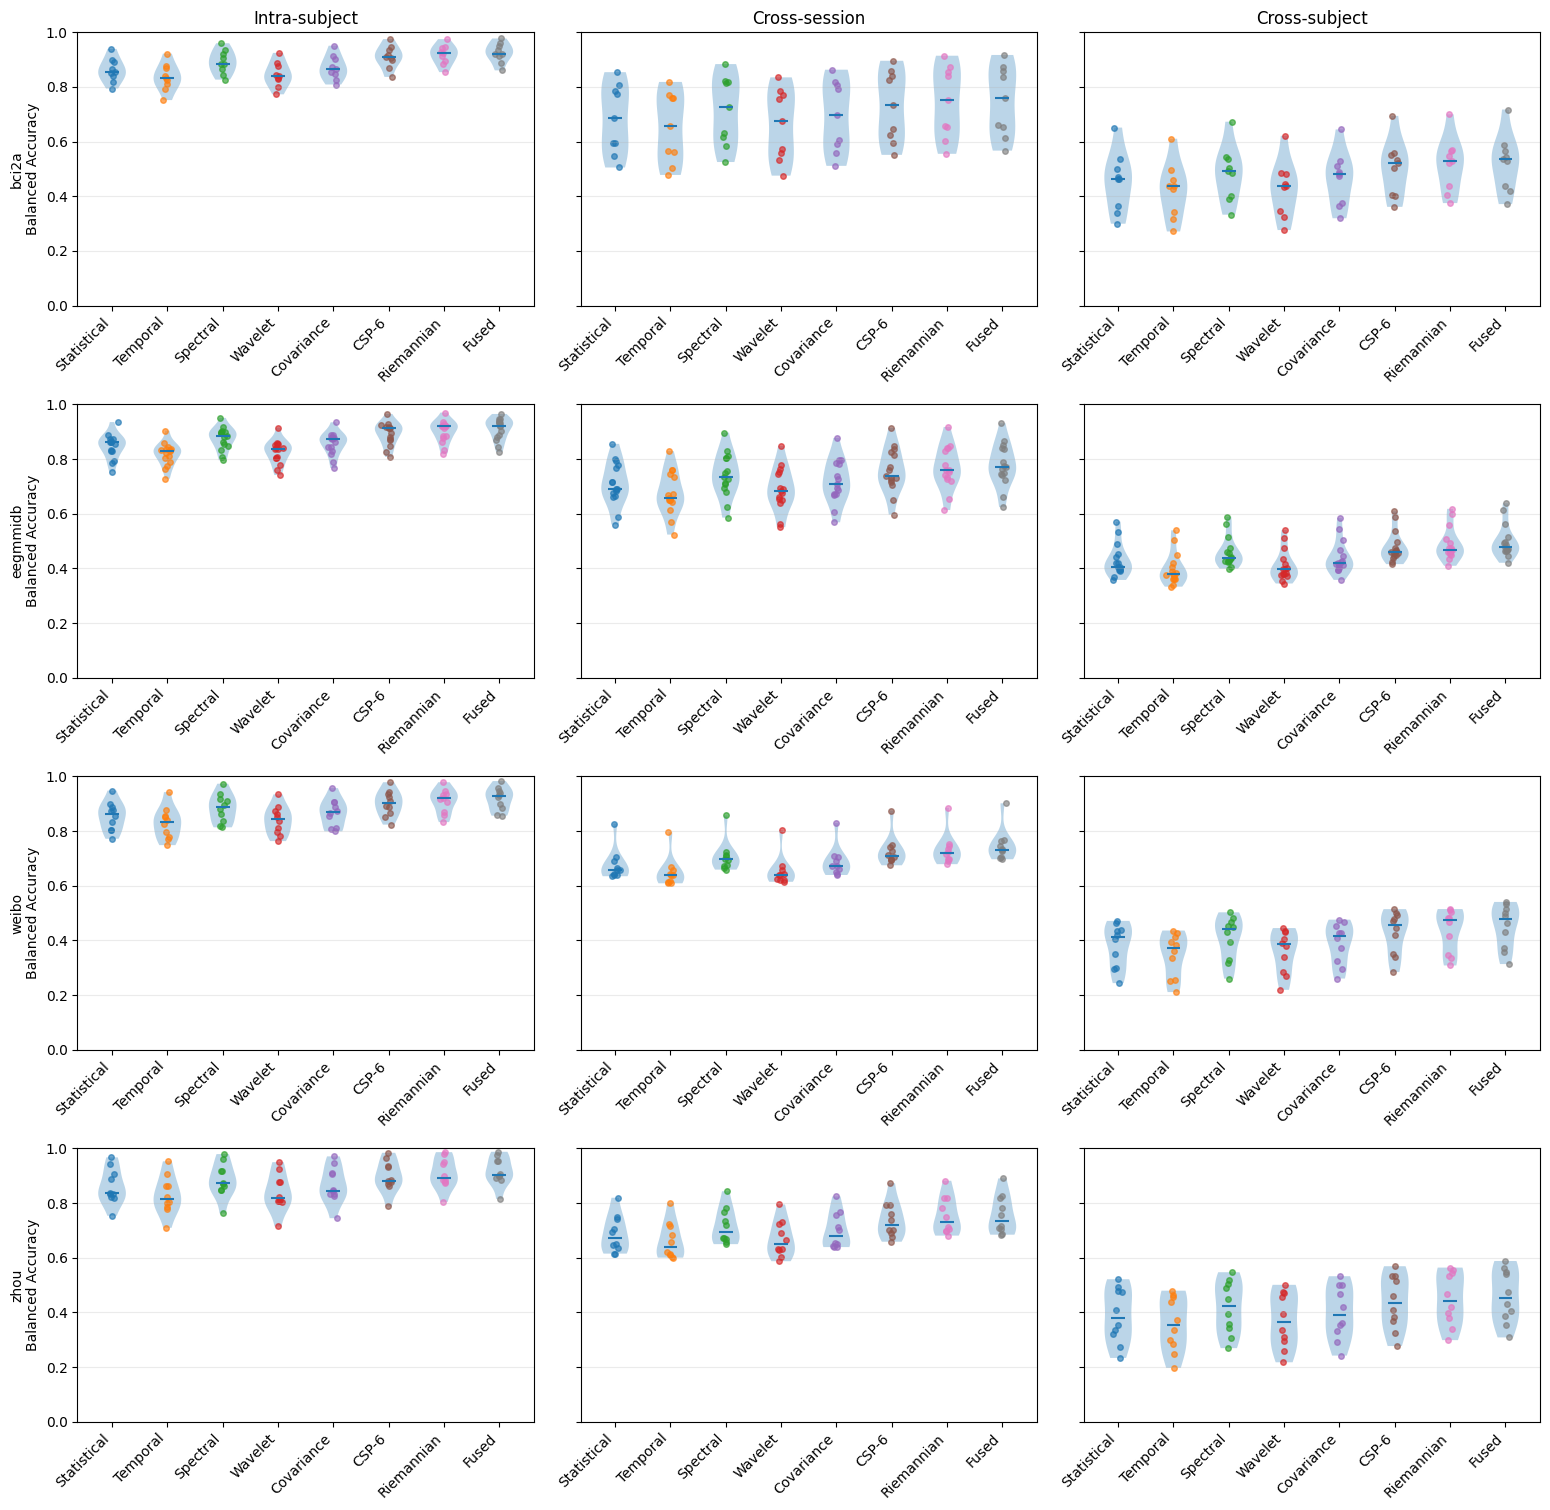

In [5]:
from pathlib import Path

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def plot_representation_generalization(subject_results):
    datasets = sorted(subject_results["Dataset"].dropna().unique())
    scenarios = [
        s for s in SCENARIOS
        if s in subject_results["Scenario"].unique()
    ]
    representations = [
        r for r in REPRESENTATIONS
        if r in subject_results["Representation"].unique()
    ]

    fig, axes = plt.subplots(
        len(datasets), len(scenarios),
        figsize=(5.2 * len(scenarios), 3.8 * len(datasets)),
        sharey=True, squeeze=False,
    )

    rng = np.random.default_rng(0)

    for i, dataset in enumerate(datasets):
        for j, scenario in enumerate(scenarios):
            ax = axes[i, j]
            subset = subject_results[
                (subject_results["Dataset"] == dataset)
                & (subject_results["Scenario"] == scenario)
            ]

            active = [
                rep for rep in representations
                if rep in subset["Representation"].values
            ]

            values = [
                subset.loc[
                    subset["Representation"] == rep,
                    "Balanced Accuracy"
                ].dropna().to_numpy()
                for rep in active
            ]

            positions = np.arange(1, len(active) + 1)
            violin_values = [
                x if len(x) > 1 else np.repeat(x, 2)
                for x in values
            ]

            if violin_values:
                ax.violinplot(
                    violin_values, positions=positions,
                    showmeans=False, showmedians=True,
                    showextrema=False,
                )

                for position, value in zip(positions, values):
                    ax.scatter(
                        position + rng.normal(0, 0.035, len(value)),
                        value, s=16, alpha=0.65,
                    )

            ax.set_xticks(positions)
            ax.set_xticklabels(active, rotation=45, ha="right")
            ax.set_ylim(0, 1)
            ax.grid(axis="y", alpha=0.25)

            if i == 0:
                ax.set_title(scenario)
            if j == 0:
                ax.set_ylabel(f"{dataset}\nBalanced Accuracy")

    fig.tight_layout()

    for ext in ["pdf", "png"]:
        fig.savefig(
            FIGURES_DIR / f"representation_generalization.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


plot_representation_generalization(representation_subjects)

# plot_best_configuration_subjects

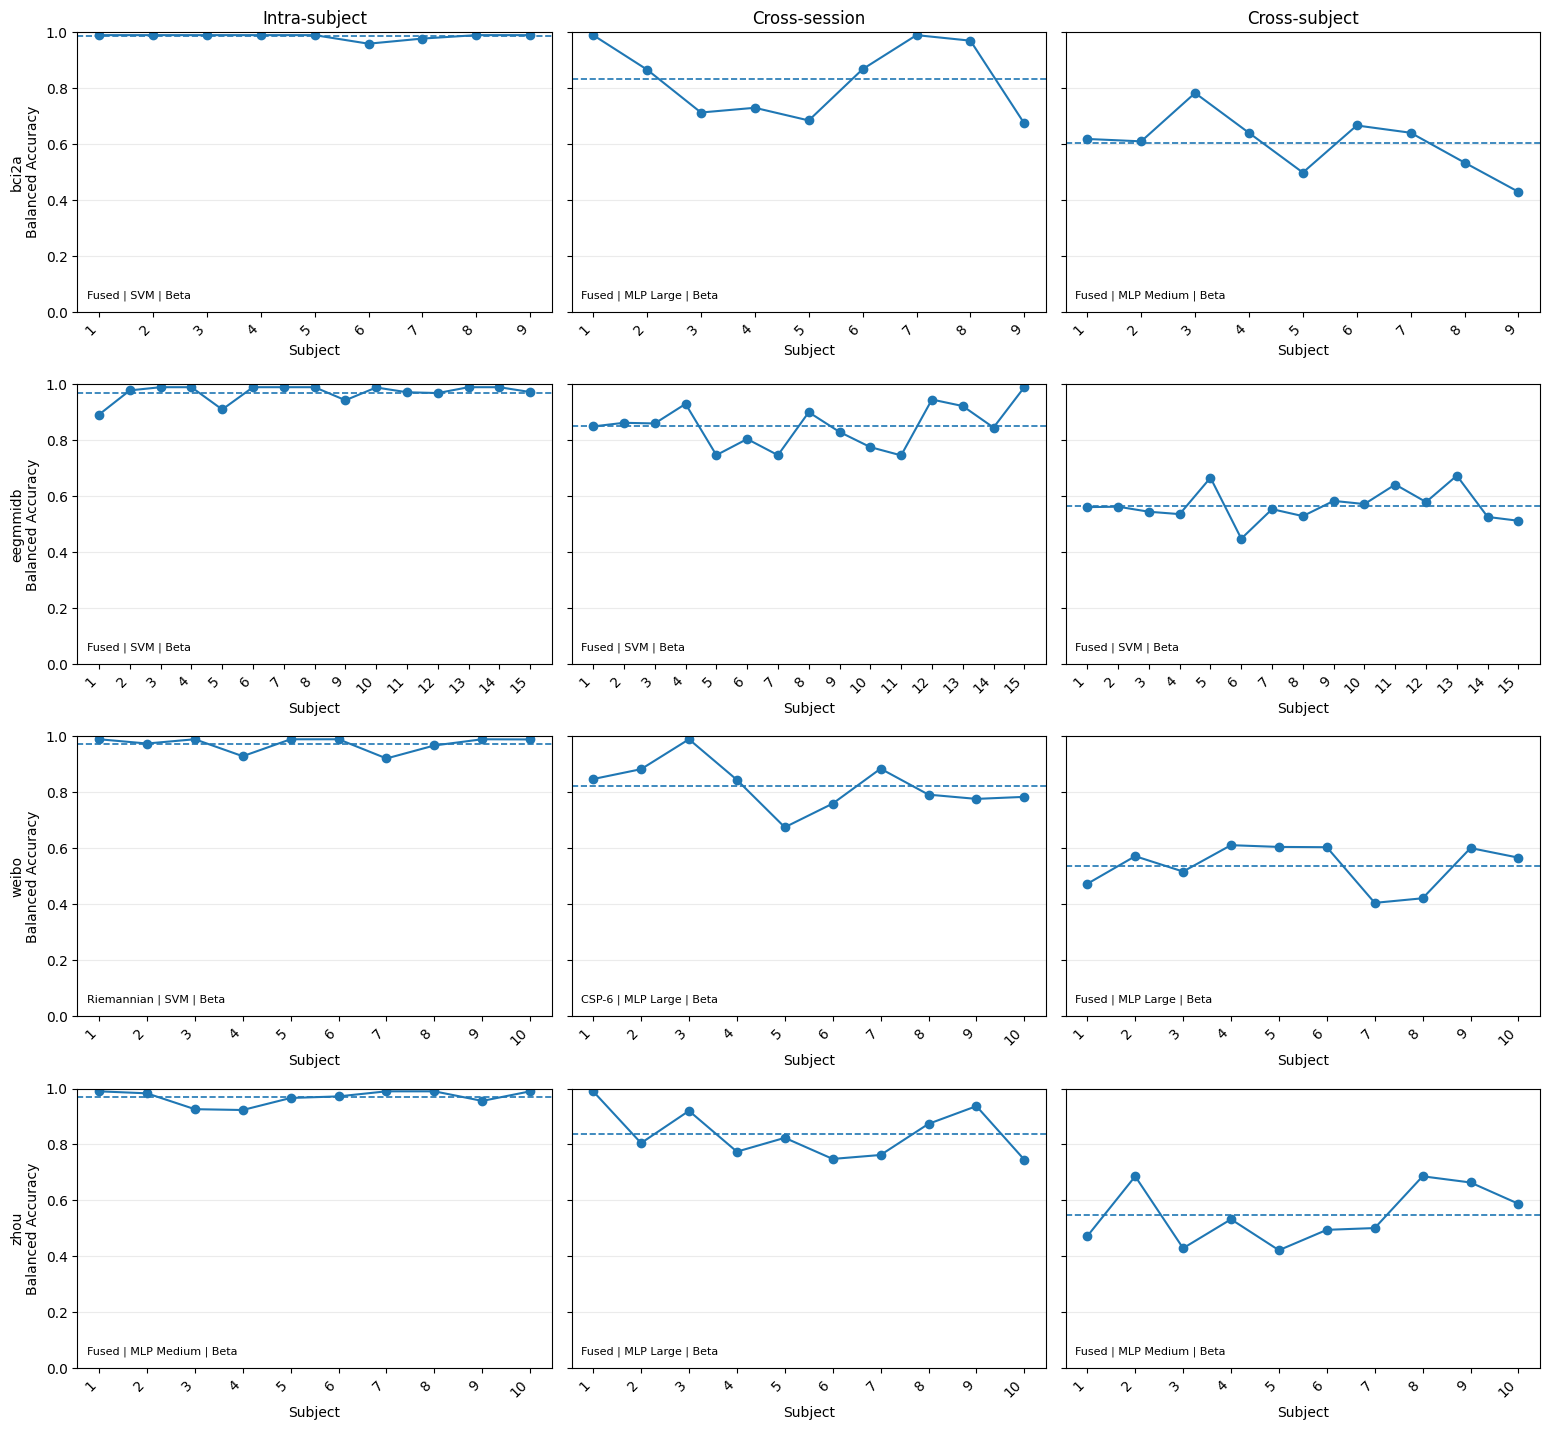

In [6]:
def subject_sort_key(value):
    text = str(value)
    try:
        return (0, float(text))
    except ValueError:
        return (1, text)


def plot_best_configuration_subjects(subject_results):
    datasets = sorted(subject_results["Dataset"].dropna().unique())
    scenarios = [
        s for s in SCENARIOS
        if s in subject_results["Scenario"].unique()
    ]

    fig, axes = plt.subplots(
        len(datasets), len(scenarios),
        figsize=(5.2 * len(scenarios), 3.6 * len(datasets)),
        sharey=True, squeeze=False,
    )

    for i, dataset in enumerate(datasets):
        for j, scenario in enumerate(scenarios):
            ax = axes[i, j]

            subset = subject_results[
                (subject_results["Dataset"] == dataset)
                & (subject_results["Scenario"] == scenario)
            ].copy()

            if subset.empty:
                ax.text(
                    0.5, 0.5, "Not available",
                    transform=ax.transAxes,
                    ha="center", va="center", fontsize=9
                )
                ax.set_xticks([])
                ax.set_yticks([])
            else:
                subset = subset.sort_values(
                    "Subject",
                    key=lambda x: x.map(subject_sort_key)
                )

                x = np.arange(len(subset))
                y = subset["Balanced Accuracy"].to_numpy()
                config = subset.iloc[0]

                ax.plot(x, y, marker="o")
                ax.axhline(np.nanmean(y), linestyle="--", linewidth=1.2)

                ax.set_xticks(x)
                ax.set_xticklabels(
                    subset["Subject"].astype(str),
                    rotation=45, ha="right"
                )

                ax.text(
                    0.02, 0.04,
                    f"{config['Representation']} | {config['Model']} | {config['Band']}",
                    transform=ax.transAxes,
                    fontsize=8,
                    va="bottom",
                )

                ax.set_ylim(0, 1)
                ax.grid(axis="y", alpha=0.25)
                ax.set_xlabel("Subject")

            if i == 0:
                ax.set_title(scenario)
            if j == 0:
                ax.set_ylabel(f"{dataset}\nBalanced Accuracy")

    fig.tight_layout()

    for ext in ["pdf", "png"]:
        fig.savefig(
            FIGURES_DIR / f"best_configuration_subjects.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


plot_best_configuration_subjects(best_configuration_subjects)

# plot_subject_rankings

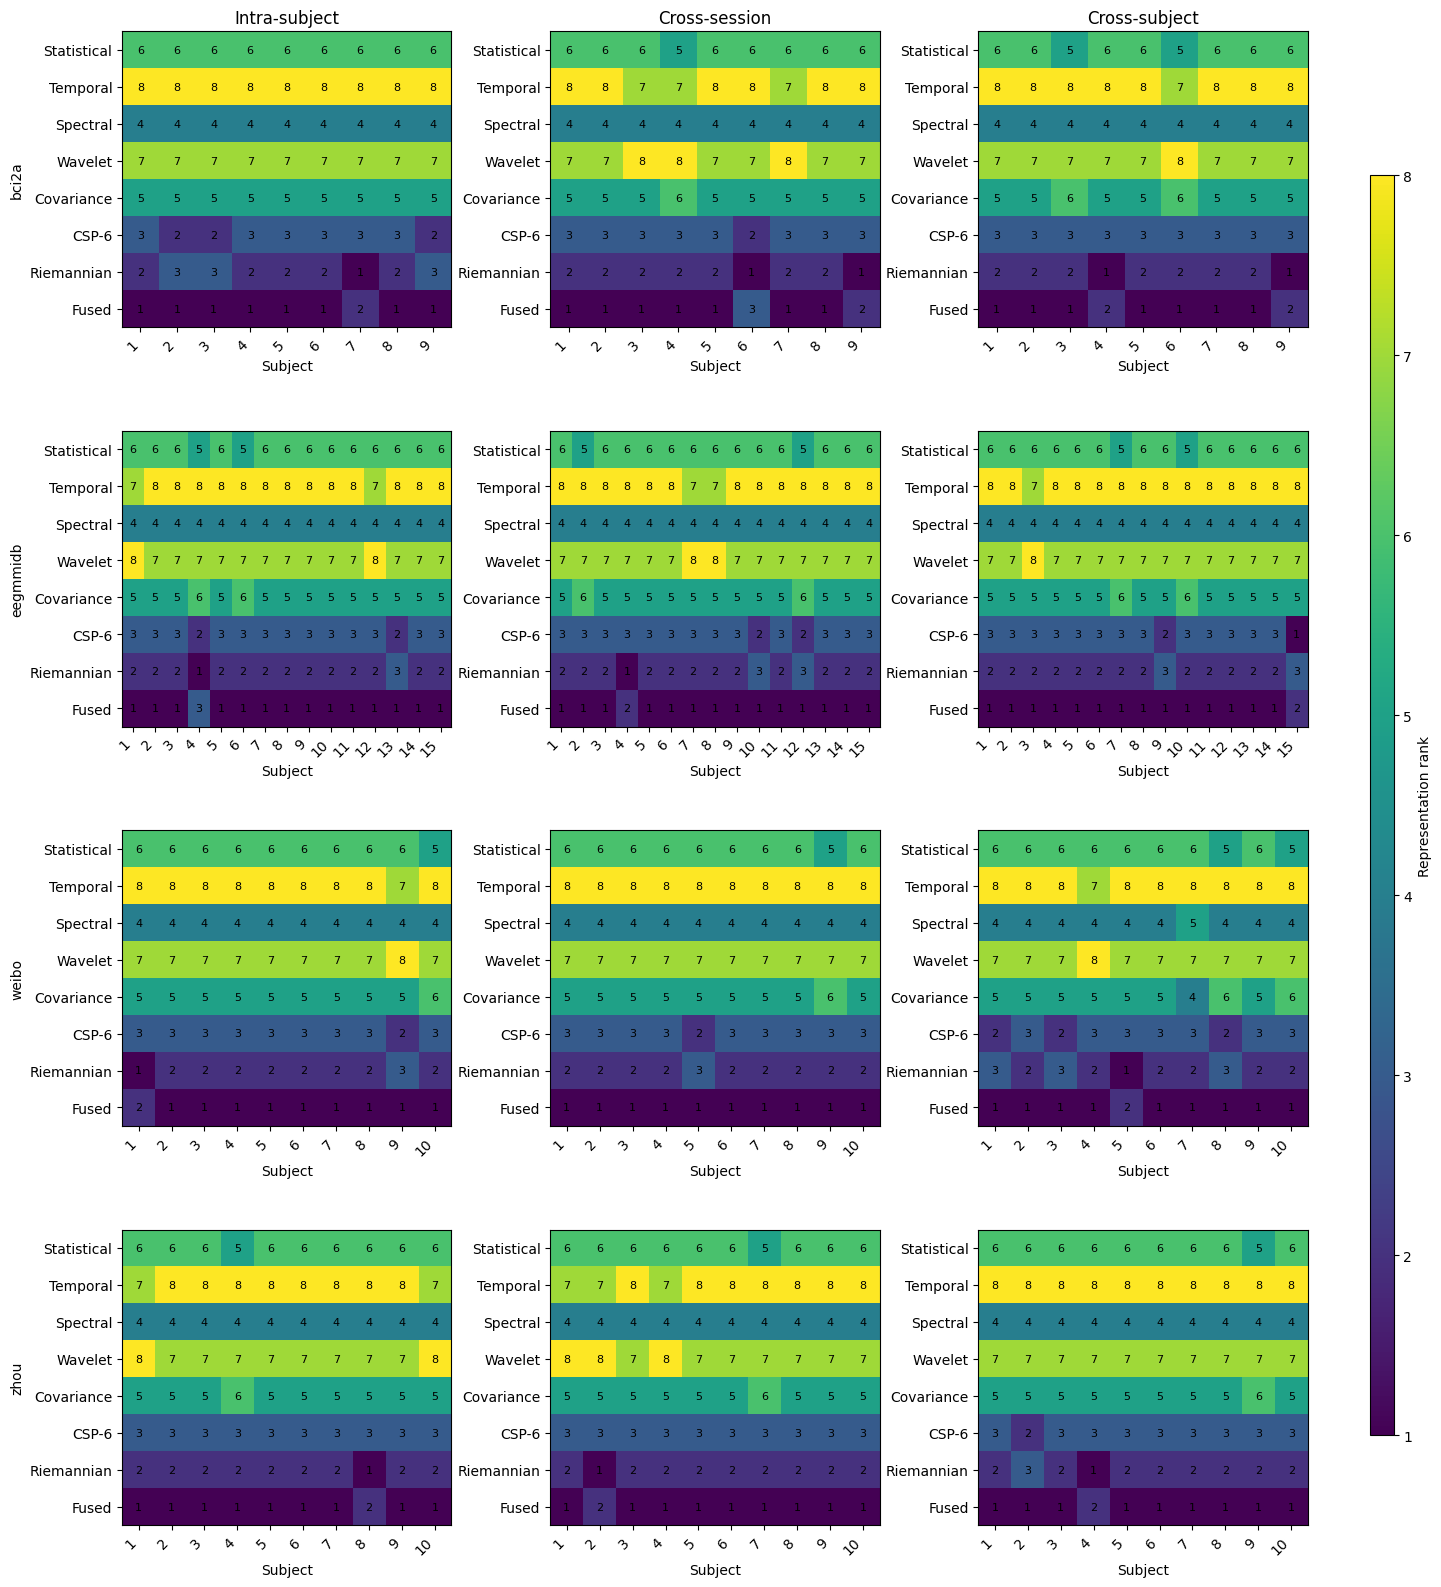

In [7]:
def plot_subject_rankings(rankings):
    datasets = sorted(rankings["Dataset"].dropna().unique())
    scenarios = [
        s for s in SCENARIOS
        if s in rankings["Scenario"].unique()
    ]
    representations = [
        r for r in REPRESENTATIONS
        if r in rankings["Representation"].unique()
    ]

    fig, axes = plt.subplots(
        len(datasets), len(scenarios),
        figsize=(5.2 * len(scenarios), 4.5 * len(datasets)),
        squeeze=False,
    )

    image = None

    for i, dataset in enumerate(datasets):
        for j, scenario in enumerate(scenarios):
            ax = axes[i, j]

            subset = rankings[
                (rankings["Dataset"] == dataset)
                & (rankings["Scenario"] == scenario)
            ]

            if subset.empty:
                ax.text(
                    0.5, 0.5, "Not available",
                    transform=ax.transAxes,
                    ha="center", va="center", fontsize=9
                )
                ax.set_xticks([])
                ax.set_yticks([])
            else:
                subjects = sorted(
                    subset["Subject"].dropna().unique(),
                    key=subject_sort_key
                )
                active = [
                    rep for rep in representations
                    if rep in subset["Representation"].values
                ]

                matrix = (
                    subset.pivot_table(
                        index="Representation",
                        columns="Subject",
                        values="Rank",
                        aggfunc="mean",
                    )
                    .reindex(index=active, columns=subjects)
                )

                if matrix.empty:
                    ax.text(
                        0.5, 0.5, "Not available",
                        transform=ax.transAxes,
                        ha="center", va="center", fontsize=9
                    )
                else:
                    image = ax.imshow(
                        matrix.to_numpy(dtype=float),
                        aspect="auto",
                        interpolation="nearest",
                    )

                    for row in range(matrix.shape[0]):
                        for col in range(matrix.shape[1]):
                            value = matrix.iloc[row, col]

                            if pd.notna(value):
                                ax.text(
                                    col, row, f"{value:.0f}",
                                    ha="center", va="center",
                                    fontsize=8,
                                )

                    ax.set_xticks(np.arange(len(subjects)))
                    ax.set_xticklabels(
                        subjects, rotation=45, ha="right"
                    )
                    ax.set_yticks(np.arange(len(active)))
                    ax.set_yticklabels(active)
                    ax.set_xlabel("Subject")

            if i == 0:
                ax.set_title(scenario)
            if j == 0:
                ax.set_ylabel(dataset)

    if image is not None:
        cax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
        fig.colorbar(image, cax=cax, label="Representation rank")

    fig.subplots_adjust(
        left=0.12, right=0.88,
        bottom=0.10, top=0.93,
        hspace=0.35, wspace=0.30,
    )

    for ext in ["pdf", "png"]:
        fig.savefig(
            FIGURES_DIR / f"subject_ranking.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


plot_subject_rankings(subject_rankings)

# plot_model_robustness

In [8]:
def _plot_delta_heatmap(ax, dataframe, column, representations, title):
    values = sorted(dataframe[column].dropna().unique())

    matrix = (
        dataframe.pivot_table(
            index="Representation", columns=column,
            values="Delta BA", aggfunc="mean",
        )
        .reindex(index=representations, columns=values)
    )

    image = ax.imshow(
        matrix.to_numpy(dtype=float),
        aspect="auto", interpolation="nearest",
        vmin=-0.15, vmax=0.15,
    )

    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            value = matrix.iloc[row, col]
            if pd.notna(value):
                ax.text(
                    col, row, f"{value:+.2f}",
                    ha="center", va="center", fontsize=7,
                )

    ax.set_xticks(np.arange(len(values)))
    ax.set_xticklabels(values, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(representations)))
    ax.set_yticklabels(representations)
    ax.set_title(title)

    return image

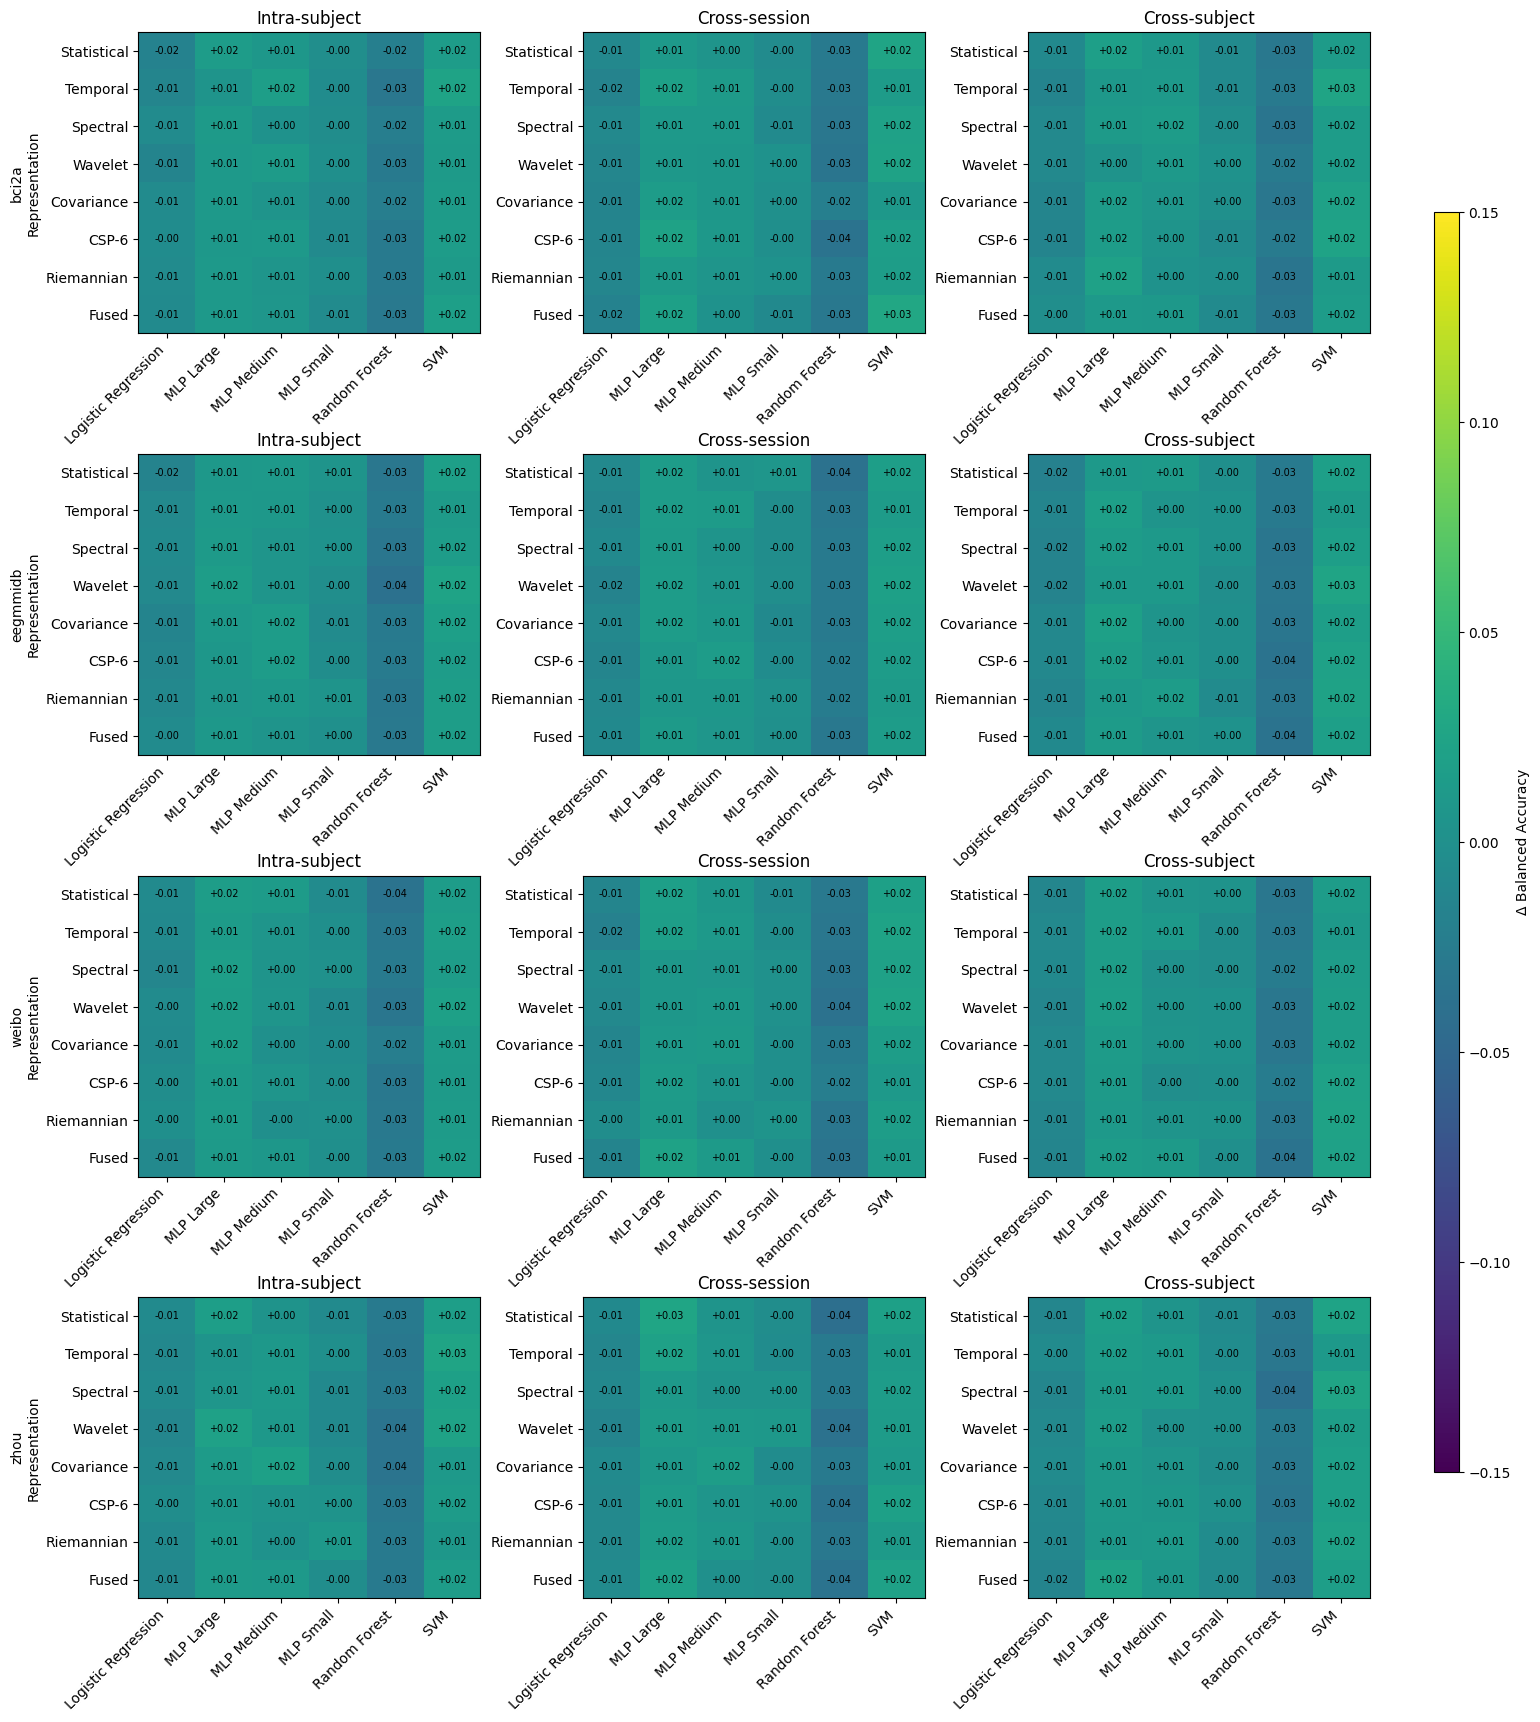

In [9]:
def plot_model_robustness(model_robustness):
    datasets = sorted(model_robustness["Dataset"].dropna().unique())
    scenarios = [
        s for s in SCENARIOS
        if s in model_robustness["Scenario"].unique()
    ]

    fig, axes = plt.subplots(
        len(datasets), len(scenarios),
        figsize=(5.4 * len(scenarios), 4.5 * len(datasets)),
        squeeze=False,
    )

    image = None

    for i, dataset in enumerate(datasets):
        for j, scenario in enumerate(scenarios):
            ax = axes[i, j]

            subset = model_robustness[
                (model_robustness["Dataset"] == dataset)
                & (model_robustness["Scenario"] == scenario)
            ]

            if subset.empty:
                ax.text(
                    0.5, 0.5, "Not available",
                    transform=ax.transAxes,
                    ha="center", va="center",
                )
                ax.set_xticks([])
                ax.set_yticks([])
                continue

            active = [
                r for r in REPRESENTATIONS
                if r in subset["Representation"].values
            ]

            image = _plot_delta_heatmap(
                ax, subset, "Model", active, scenario
            )

            if j == 0:
                ax.set_ylabel(f"{dataset}\nRepresentation")

    if image is not None:
        cax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
        fig.colorbar(image, cax=cax, label="Δ Balanced Accuracy")

    fig.subplots_adjust(
        left=0.12, right=0.88,
        bottom=0.08, top=0.95,
        hspace=0.40, wspace=0.30,
    )

    for ext in ["pdf", "png"]:
        fig.savefig(
            FIGURES_DIR / f"model_robustness.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


plot_model_robustness(model_robustness)

# plot_band_robustness

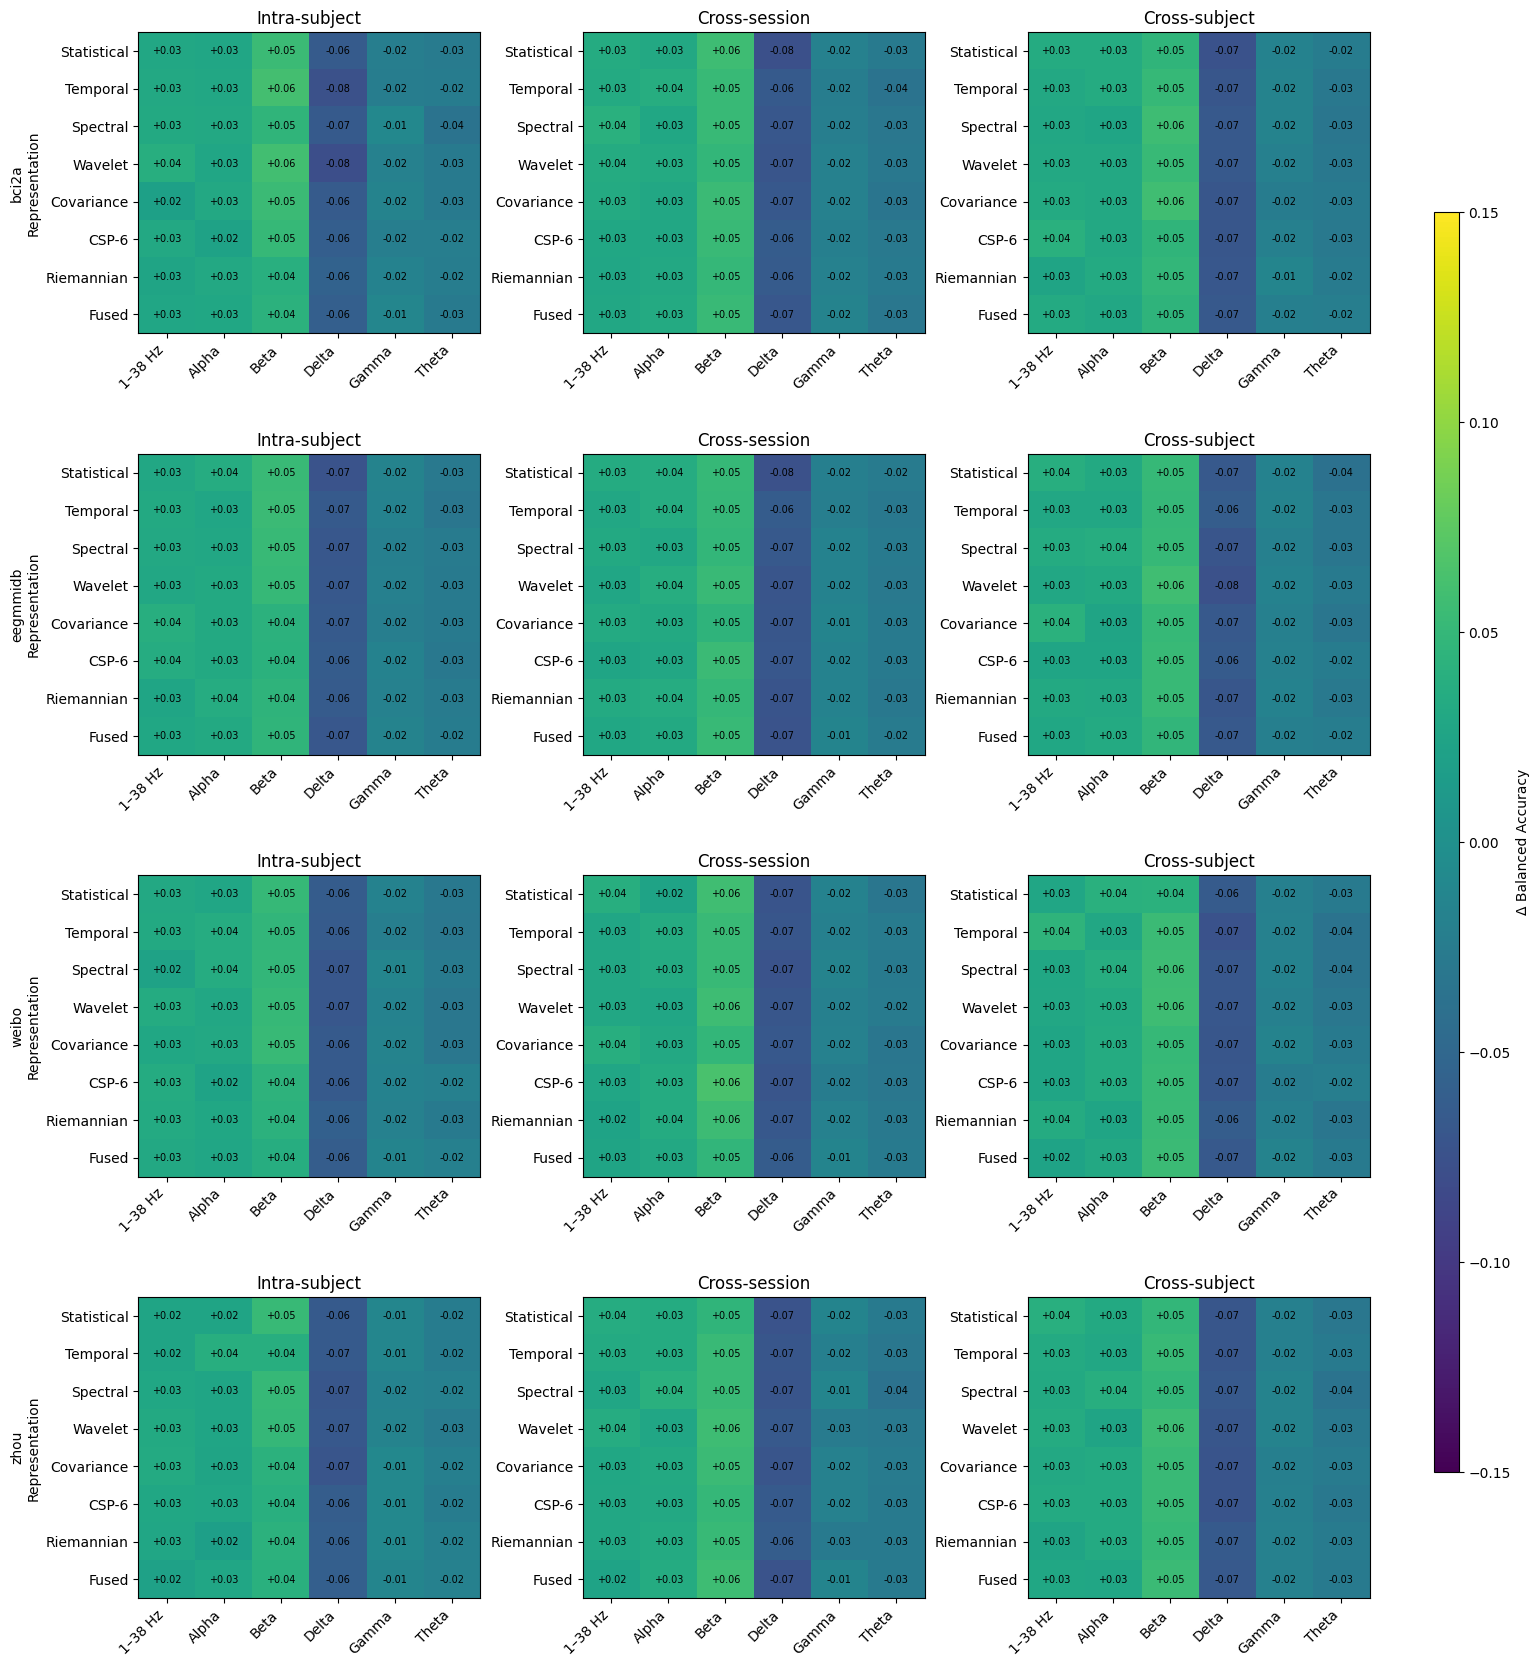

In [10]:
def plot_band_robustness(band_robustness):
    datasets = sorted(band_robustness["Dataset"].dropna().unique())
    scenarios = [
        s for s in SCENARIOS
        if s in band_robustness["Scenario"].unique()
    ]

    fig, axes = plt.subplots(
        len(datasets), len(scenarios),
        figsize=(5.4 * len(scenarios), 4.5 * len(datasets)),
        squeeze=False,
    )

    image = None

    for i, dataset in enumerate(datasets):
        for j, scenario in enumerate(scenarios):
            ax = axes[i, j]

            subset = band_robustness[
                (band_robustness["Dataset"] == dataset)
                & (band_robustness["Scenario"] == scenario)
            ]

            if subset.empty:
                ax.text(
                    0.5, 0.5, "Not available",
                    transform=ax.transAxes,
                    ha="center", va="center",
                )
                ax.set_xticks([])
                ax.set_yticks([])
                continue

            active = [
                r for r in REPRESENTATIONS
                if r in subset["Representation"].values
            ]

            image = _plot_delta_heatmap(
                ax, subset, "Band", active, scenario
            )

            if j == 0:
                ax.set_ylabel(f"{dataset}\nRepresentation")

    if image is not None:
        cax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
        fig.colorbar(image, cax=cax, label="Δ Balanced Accuracy")

    fig.subplots_adjust(
        left=0.12, right=0.88,
        bottom=0.08, top=0.95,
        hspace=0.40, wspace=0.30,
    )

    for ext in ["pdf", "png"]:
        fig.savefig(
            FIGURES_DIR / f"band_robustness.{ext}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


plot_band_robustness(band_robustness)

# Tables

In [11]:
# Synthetic training performance
train_subjects = representation_subjects.copy()

rng_train = np.random.default_rng(123)

train_subjects["Balanced Accuracy"] = np.clip(
    train_subjects["Balanced Accuracy"]
    + rng_train.uniform(0.05, 0.15, len(train_subjects)),
    0, 1,
)

def summarize_ba(df, prefix):
    return (
        df.groupby(["Dataset", "Representation", "Scenario"])
        .agg(**{
            f"{prefix}_ba_mean": ("Balanced Accuracy", "mean"),
            f"{prefix}_ba_std": ("Balanced Accuracy", "std"),
        })
        .reset_index()
    )

train_summary = summarize_ba(train_subjects, "train")
test_summary = summarize_ba(representation_subjects, "test")

combined = train_summary.merge(
    test_summary,
    on=["Dataset", "Representation", "Scenario"],
    how="outer",
)

rows = []

for (dataset, representation), group in combined.groupby(
    ["Dataset", "Representation"]
):
    row = {"Dataset": dataset, "Representation": representation}

    for scenario in SCENARIOS:
        current = group[group["Scenario"] == scenario]

        for split in ["Train", "Test"]:
            prefix = split.lower()
            row[f"{scenario} {split} BA Mean"] = (
                current[f"{prefix}_ba_mean"].iloc[0]
                if not current.empty else np.nan
            )
            row[f"{scenario} {split} BA Std"] = (
                current[f"{prefix}_ba_std"].iloc[0]
                if not current.empty else np.nan
            )

    rows.append(row)

representation_summary = pd.DataFrame(rows)

display(representation_summary.head())

,Dataset,Representation,Intra-subject Train BA Mean,Intra-subject Train BA Std,Intra-subject Test BA Mean,Intra-subject Test BA Std,Cross-session Train BA Mean,Cross-session Train BA Std,Cross-session Test BA Mean,Cross-session Test BA Std,Cross-subject Train BA Mean,Cross-subject Train BA Std,Cross-subject Test BA Mean,Cross-subject Test BA Std
0,bci2a,CSP-6,0.976235,0.034796,0.910732,0.041059,0.830210,0.132753,0.730330,0.128999,0.590685,0.122808,0.503631,0.102063
1,bci2a,Covariance,0.976154,0.032336,0.871044,0.044767,0.785944,0.138769,0.694312,0.130830,0.572686,0.092409,0.465779,0.098837
2,bci2a,Fused,0.986961,0.026016,0.925412,0.036102,0.841802,0.107043,0.749186,0.128055,0.613833,0.114772,0.523469,0.103198
3,bci2a,Riemannian,0.987585,0.017776,0.918352,0.036362,0.843538,0.131743,0.744823,0.130962,0.611174,0.111453,0.516610,0.099023
4,bci2a,Spectral,0.969999,0.033102,0.891488,0.042988,0.814586,0.111945,0.713811,0.127015,0.587068,0.100051,0.484533,0.100708


In [12]:
# Best configurations
best_configurations = (
    configuration_subjects
    .groupby(
        ["Dataset", "Scenario", "Representation", "Model", "Band"],
        as_index=False,
    )
    .agg(
        ba_mean=("Balanced Accuracy", "mean"),
        ba_std=("Balanced Accuracy", "std"),
        f1_mean=("Macro-F1", "mean"),
        f1_std=("Macro-F1", "std"),
        auc_mean=("AUC", "mean"),
        auc_std=("AUC", "std"),
        subjects=("Subject", "nunique"),
    )
    .sort_values(
        ["Dataset", "Scenario", "ba_mean", "f1_mean", "auc_mean"],
        ascending=[True, True, False, False, False],
    )
    .groupby(["Dataset", "Scenario"], as_index=False)
    .head(1)
    .rename(columns={
        "Band": "Preprocessing",
        "ba_mean": "BA Mean",
        "ba_std": "BA Std",
        "f1_mean": "F1 Mean",
        "f1_std": "F1 Std",
        "auc_mean": "AUC Mean",
        "auc_std": "AUC Std",
        "subjects": "Subjects",
    })
    .reset_index(drop=True)
)

# Subject ranking summary
ranking_summary = (
    subject_rankings
    .groupby(
        ["Dataset", "Scenario", "Representation"],
        as_index=False,
    )
    .agg(
        **{
            "Mean Rank": ("Rank", "mean"),
            "Rank Variability": ("Rank", "std"),
            "Subjects": ("Subject", "nunique"),
            "Best Count": ("Rank", lambda x: (x == 1).sum()),
            "Top-3 Count": ("Rank", lambda x: (x <= 3).sum()),
        }
    )
)

ranking_summary["Best (%)"] = (
    100 * ranking_summary["Best Count"] / ranking_summary["Subjects"]
)

ranking_summary["Top-3 (%)"] = (
    100 * ranking_summary["Top-3 Count"] / ranking_summary["Subjects"]
)

ranking_summary = ranking_summary[
    [
        "Dataset", "Scenario", "Representation",
        "Mean Rank", "Rank Variability",
        "Best (%)", "Top-3 (%)", "Subjects",
    ]
]

display(best_configurations.head())
display(ranking_summary.head())

,Dataset,Scenario,Representation,Model,Preprocessing,BA Mean,BA Std,F1 Mean,F1 Std,AUC Mean,AUC Std,Subjects
0,bci2a,Cross-session,Fused,MLP Large,Beta,0.832061,0.133414,0.810256,0.125865,0.875931,0.115130,9
1,bci2a,Cross-subject,Fused,MLP Medium,Beta,0.602778,0.103211,0.582231,0.100566,0.691622,0.124382,9
2,bci2a,Intra-subject,Fused,SVM,Beta,0.985233,0.010508,0.959475,0.010500,1.000000,0.000000,9
3,eegmmidb,Cross-session,Fused,SVM,Beta,0.850650,0.077090,0.823619,0.077822,0.918952,0.072337,15
4,eegmmidb,Cross-subject,Fused,SVM,Beta,0.566363,0.059244,0.554244,0.066984,0.636257,0.075645,15


,Dataset,Scenario,Representation,Mean Rank,Rank Variability,Best (%),Top-3 (%),Subjects
0,bci2a,Cross-session,CSP-6,2.888889,0.333333,0.000000,100.0,9
1,bci2a,Cross-session,Covariance,5.111111,0.333333,0.000000,0.0,9
2,bci2a,Cross-session,Fused,1.333333,0.707107,77.777778,100.0,9
3,bci2a,Cross-session,Riemannian,1.777778,0.440959,22.222222,100.0,9
4,bci2a,Cross-session,Spectral,4.000000,0.000000,0.000000,0.0,9


In [13]:
from scipy import stats

friedman_results = []

for (dataset, scenario), group in representation_subjects.groupby(
    ["Dataset", "Scenario"]
):
    pivot = (
        group.pivot_table(
            index="Subject",
            columns="Representation",
            values="Balanced Accuracy",
            aggfunc="mean",
        )
        .dropna()
    )

    if pivot.shape[0] < 2 or pivot.shape[1] < 3:
        continue

    statistic, p_value = stats.friedmanchisquare(
        *[pivot[col].to_numpy() for col in pivot.columns]
    )

    friedman_results.append({
        "Dataset": dataset,
        "Scenario": scenario,
        "Subjects": len(pivot),
        "Representations": pivot.shape[1],
        "Statistic": statistic,
        "P-value": p_value,
    })

friedman_results = pd.DataFrame(friedman_results)

display(friedman_results)

,Dataset,Scenario,Subjects,Representations,Statistic,P-value
0,bci2a,Cross-session,9,8,60.962963,9.692859e-11
1,bci2a,Cross-subject,9,8,61.666667,7.009606e-11
2,bci2a,Intra-subject,9,8,61.925926,6.220165e-11
3,eegmmidb,Cross-session,15,8,102.911111,2.699830e-19
4,eegmmidb,Cross-subject,15,8,102.933333,2.671411e-19
5,eegmmidb,Intra-subject,15,8,102.600000,3.130910e-19
6,weibo,Cross-session,10,8,69.400000,1.953080e-12
7,weibo,Cross-subject,10,8,67.700000,4.302677e-12
8,weibo,Intra-subject,10,8,68.766667,2.621710e-12
9,zhou,Cross-session,10,8,68.700000,2.704202e-12


# generate_representation_summary_latex

In [14]:
from pathlib import Path

TABLES_DIR = Path("tables")
TABLES_DIR.mkdir(parents=True, exist_ok=True)


def _latex_escape(value):
    if pd.isna(value):
        return "-"

    text = str(value)
    for old, new in {
        "&": r"\&",
        "%": r"\%",
        "_": r"\_",
        "#": r"\#",
    }.items():
        text = text.replace(old, new)

    return text


def _mean_std(mean, std):
    if pd.isna(mean):
        return "-"
    return f"{mean:.3f}" if pd.isna(std) else f"{mean:.3f} $\\pm$ {std:.3f}"


def generate_representation_summary_latex(summary):
    lines = [
        r"\begin{table*}[t]",
        r"\centering",
        r"\small",
        r"\caption{Balanced Accuracy of the evaluated EEG representations across generalization regimes. Values are reported as mean $\pm$ standard deviation across subjects.}",
        r"\label{tab:representation_summary}",
        r"\begin{tabular}{llcccccc}",
        r"\toprule",
        r"\textbf{Dataset} & \textbf{Representation} &",
        r"\multicolumn{2}{c}{\textbf{Intra-subject}} &",
        r"\multicolumn{2}{c}{\textbf{Cross-session}} &",
        r"\multicolumn{2}{c}{\textbf{Cross-subject}} \\",
        r"\cmidrule(lr){3-4}\cmidrule(lr){5-6}\cmidrule(lr){7-8}",
        r"& & \textbf{Train BA} & \textbf{Test BA} &",
        r"\textbf{Train BA} & \textbf{Test BA} &",
        r"\textbf{Train BA} & \textbf{Test BA} \\",
        r"\midrule",
    ]

    for dataset, group in summary.groupby("Dataset", sort=True):
        first = True

        for _, row in group.iterrows():
            values = [
                _latex_escape(dataset) if first else "",
                _latex_escape(row["Representation"]),
            ]

            for scenario in SCENARIOS:
                for split in ["Train", "Test"]:
                    values.append(_mean_std(
                        row.get(f"{scenario} {split} BA Mean"),
                        row.get(f"{scenario} {split} BA Std"),
                    ))

            lines.append(" & ".join(values) + r" \\")
            first = False

        lines.append(r"\midrule")

    lines[-1] = r"\bottomrule"
    lines += [r"\end{tabular}", r"\end{table*}"]

    path = TABLES_DIR / "representation_summary.tex"
    path.write_text("\n".join(lines), encoding="utf-8")

    print(f"Saved to: {path.resolve()}")


generate_representation_summary_latex(representation_summary)

Saved to: /home/odake/projects/EEG-Experiments/jupyter/tables/representation_summary.tex


# generate_best_configurations_latex

In [15]:
def generate_best_configurations_latex(best):
    lines = [
        r"\begin{table*}[t]",
        r"\centering",
        r"\small",
        r"\caption{Best observed configuration for each dataset and generalization regime.}",
        r"\label{tab:best_configurations}",
        r"\begin{tabular}{lllllcc}",
        r"\toprule",
        r"\textbf{Dataset} & \textbf{Regime} & \textbf{Representation} &",
        r"\textbf{Classifier} & \textbf{Preprocessing} & \textbf{BA} & \textbf{F1} \\",
        r"\midrule",
    ]

    for dataset, group in best.groupby("Dataset", sort=True):
        first = True

        for _, row in group.iterrows():
            values = [
                _latex_escape(dataset) if first else "",
                _latex_escape(row["Scenario"]),
                _latex_escape(row["Representation"]),
                _latex_escape(row["Model"]),
                _latex_escape(row["Preprocessing"]),
                _mean_std(row["BA Mean"], row["BA Std"]),
                _mean_std(row["F1 Mean"], row["F1 Std"]),
            ]

            lines.append(" & ".join(values) + r" \\")
            first = False

        lines.append(r"\midrule")

    lines[-1] = r"\bottomrule"
    lines += [r"\end{tabular}", r"\end{table*}"]

    path = TABLES_DIR / "best_configurations.tex"
    path.write_text("\n".join(lines), encoding="utf-8")

    print(f"Saved to: {path.resolve()}")


generate_best_configurations_latex(best_configurations)

Saved to: /home/odake/projects/EEG-Experiments/jupyter/tables/best_configurations.tex


# generate_subject_ranking_latex

In [16]:
def generate_subject_ranking_latex(summary):
    lines = [
        r"\begin{table*}[t]",
        r"\centering",
        r"\scriptsize",
        r"\caption{Summary of subject-specific representation rankings.}",
        r"\label{tab:subject_ranking_summary}",
        r"\begin{tabular}{lllcccc}",
        r"\toprule",
        r"\textbf{Dataset} & \textbf{Regime} & \textbf{Representation} &",
        r"\textbf{Mean Rank} & \textbf{Rank Variability} &",
        r"\textbf{Best (\%)} & \textbf{Top-3 (\%)} \\",
        r"\midrule",
    ]

    scenario_order = ["Intra-subject", "Cross-session", "Cross-subject"]

    for dataset, group in summary.groupby("Dataset", sort=True):
        first_dataset = True

        for scenario in scenario_order:
            subset = group[group["Scenario"] == scenario]
            if subset.empty:
                continue

            if not first_dataset:
                lines.append(r"\addlinespace[3pt]")

            first_scenario = True

            for _, row in subset.sort_values("Representation").iterrows():
                values = [
                    _latex_escape(dataset) if first_dataset else "",
                    _latex_escape(scenario) if first_scenario else "",
                    _latex_escape(row["Representation"]),
                    f"{row['Mean Rank']:.2f}",
                    f"{row['Rank Variability']:.2f}",
                    f"{row['Best (%)']:.1f}",
                    f"{row['Top-3 (%)']:.1f}",
                ]

                lines.append(" & ".join(values) + r" \\")
                first_dataset = False
                first_scenario = False

        lines.append(r"\midrule")

    lines[-1] = r"\bottomrule"
    lines += [r"\end{tabular}", r"\end{table*}"]

    path = TABLES_DIR / "subject_ranking_summary.tex"
    path.write_text("\n".join(lines), encoding="utf-8")
    print(f"Saved to: {path.resolve()}")


generate_subject_ranking_latex(ranking_summary)

Saved to: /home/odake/projects/EEG-Experiments/jupyter/tables/subject_ranking_summary.tex


# generate_statistics_latex

In [17]:
def generate_statistics_latex(friedman_results):
    lines = [
        r"\begin{table}[t]",
        r"\centering",
        r"\small",
        r"\caption{Friedman tests for differences among EEG representations.}",
        r"\label{tab:friedman_tests}",
        r"\begin{tabular}{llccc}",
        r"\toprule",
        r"\textbf{Dataset} & \textbf{Regime} & \textbf{$\chi^2_F$} & "
        r"\textbf{$p$} & \textbf{Subjects} \\",
        r"\midrule",
    ]

    for _, row in friedman_results.iterrows():
        p = row["P-value"]
        p_text = r"$<0.001$" if p < 0.001 else f"{p:.3f}"

        values = [
            _latex_escape(row["Dataset"]),
            _latex_escape(row["Scenario"]),
            f"{row['Statistic']:.2f}",
            p_text,
            str(int(row["Subjects"])),
        ]

        lines.append(" & ".join(values) + r" \\")

    lines += [
        r"\bottomrule",
        r"\end{tabular}",
        r"\end{table}",
    ]

    path = TABLES_DIR / "friedman_tests.tex"
    path.write_text("\n".join(lines), encoding="utf-8")

    print(f"Saved to: {path.resolve()}")


generate_statistics_latex(friedman_results)

Saved to: /home/odake/projects/EEG-Experiments/jupyter/tables/friedman_tests.tex
